# Evidencia clase 29/10/26 — Otros métodos de diseño FIR

Además del diseño por **ventanas** (`firwin2`), vemos dos métodos que plantean el diseño como un problema de **optimización** sobre la respuesta en frecuencia:

1. **Cuadrados mínimos (LS, least squares)** — `sig.firls`: minimiza la **energía** del error (integral del error cuadrático ponderado) en las bandas especificadas.
2. **Parks-McClellan (equiripple, Remez exchange)** — `sig.remez`: minimiza el **máximo** error ponderado (criterio minimax). El resultado tiene ripple de igual amplitud en cada banda.

En ambos se pueden **ponderar** las bandas con un peso $W$: un peso mayor en una banda hace que el error ahí sea más "caro" y el algoritmo lo achique a costa de las otras.

Uso la misma plantilla pasabajos para el ECG ($f_s = 1000$ Hz):
- Banda de paso: $0$ a $w_p = 35$ Hz, atenuación máxima $G_{pass} = 3$ dB
- Banda de rechazo: desde $w_s = 50$ Hz, atenuación mínima $G_{stop} = 40$ dB

Referencia: [notebooks de PyTC2](https://pytc2.readthedocs.io/en/latest/notebooks/principal.html) — *Diseño por cuadrados mínimos ponderados (WLS)* y *Algoritmo Parks-McClellan (equiripple)*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal as sig
import scipy.io as sio
from matplotlib.patches import Rectangle
from pytc2.filtros_digitales import fir_design_ls, fir_design_pm

fs_ecg = 1000 # Hz

mat_struct = sio.loadmat('../Extra/TS5/ECG_TP4.mat')
ecg_one_lead = mat_struct['ecg_lead'].flatten() * 1.0
N = len(ecg_one_lead)

wp = 35 #[Hz]
ws = 50 #[Hz]
Gpass = 3
Gstop = 40
ripple = Gpass
att = Gstop

## Funciones de visualización y verificación

In [2]:
y_min, y_max = -100, 5


def calc_freq_fir( bfir ):

    # Respuesta en frecuencia en Hz, de 0 a Nyquist
    resp_freq = sig.freqz(bfir, 1, worN=8192, fs=fs_ecg)

    return resp_freq


def calc_resp( resp_freq, leg_str, fig_n_axes ):

    f, h = resp_freq

    # Módulo en dB y fase desenrollada en radianes
    modulo_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    fase_rad = np.unwrap(np.angle(h))

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # --- Módulo ---
    ax_mod.plot(f, modulo_db, linewidth=1.5, label= leg_str )
    ax_mod.set_ylim(y_min, y_max)
    ax_mod.set_ylabel("Módulo (dB)")
    ax_mod.set_title("Respuesta en frecuencia y plantilla")
    ax_mod.grid(True)

    # --- Fase ---
    ax_fase.plot(f, fase_rad, label= leg_str, linewidth=1.2)
    ax_fase.set_xlabel("Frecuencia (Hz)")
    ax_fase.set_ylabel("Fase (rad)")
    ax_fase.grid(True)


def plot_plantilla( fig_n_axes ):

    (fig, (ax_mod, ax_fase)) = fig_n_axes

    # Banda pasante: zona no permitida por debajo de -ripple
    rect_pasante = Rectangle(
        (0, y_min), wp, -ripple - y_min,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2 , label = 'Plantilla'
    )
    ax_mod.add_patch(rect_pasante)

    # Banda de rechazo: zona no permitida por encima de -att
    rect_rechazo = Rectangle(
        (ws, -att), fs_ecg / 2 - ws, y_max + att,
        facecolor="red", alpha=0.12,
        edgecolor="red", hatch="xxx", linewidth=1.2
    )
    ax_mod.add_patch(rect_rechazo)

    for ax in (ax_mod, ax_fase):
        ax.axvline(wp, color='k', ls=':', lw=1)
        ax.axvline(ws, color='k', ls=':', lw=1)

    ax_mod.legend(loc='lower left', fontsize=8)


def graficar_filtros( filtros, zoom=False ):
    # filtros: lista de (coeficientes, etiqueta)

    fig_n_axes = plt.subplots(2, 1, sharex=True, figsize=(10, 7), constrained_layout=True)

    for b, leg_str in filtros:
        calc_resp( calc_freq_fir(b), leg_str, fig_n_axes )

    plot_plantilla(fig_n_axes)

    (fig, (ax_mod, ax_fase)) = fig_n_axes
    if zoom:
        # solo interesa la zona de transición
        ax_mod.set_xlim(25, 60)
        ax_mod.set_ylim(-70, 5)
        ax_fase.set_ylim(-30, 0)

    plt.show()


def verificar( b, nombre ):

    f, h = calc_freq_fir(b)
    mod_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    en_wp = np.interp(wp, f, mod_db)
    ripple_paso = mod_db[f <= wp].max() - mod_db[f <= wp].min()
    peor_rechazo = mod_db[f >= ws].max()
    cumple = (en_wp >= -ripple) and (peor_rechazo <= -att)
    print(f'{nombre:24s} taps={len(b):3d}   |H(wp)| = {en_wp:6.2f} dB   ripple paso = {ripple_paso:5.2f} dB   max en rechazo = {peor_rechazo:7.2f} dB   -> {"cumple" if cumple else "NO cumple"}')

    return cumple

## 1. Cuadrados mínimos: `sig.firls`

`firls(numtaps, bands, desired, weight, fs)`:
- `bands`: bordes de cada banda, de a pares. Para el pasabajos: $[0, w_p]$ (paso) y $[w_s, f_s/2]$ (rechazo). **El tramo entre $w_p$ y $w_s$ queda libre** ("don't care"): no entra en el error.
- `desired`: ganancia deseada en cada borde → `[1, 1, 0, 0]`.
- `weight`: un peso por banda.
- `numtaps` tiene que ser **impar** (FIR tipo I).

### Primer intento en clase: sin banda de transición

En clase se probó `bands = [0, wp, wp, fs/2]`, es decir con $w_s = w_p$. Eso le pide al filtro un **escalón ideal** en 35 Hz: el error LS se concentra en el salto y aparece el fenómeno de Gibbs, igual que con una ventana rectangular. No cumple la plantilla.

firls sin transición     taps=191   |H(wp)| =  -5.97 dB   ripple paso =  6.59 dB   max en rechazo =  -28.84 dB   -> NO cumple
firls wp-ws              taps=191   |H(wp)| =  -0.07 dB   ripple paso =  0.10 dB   max en rechazo =  -43.88 dB   -> cumple


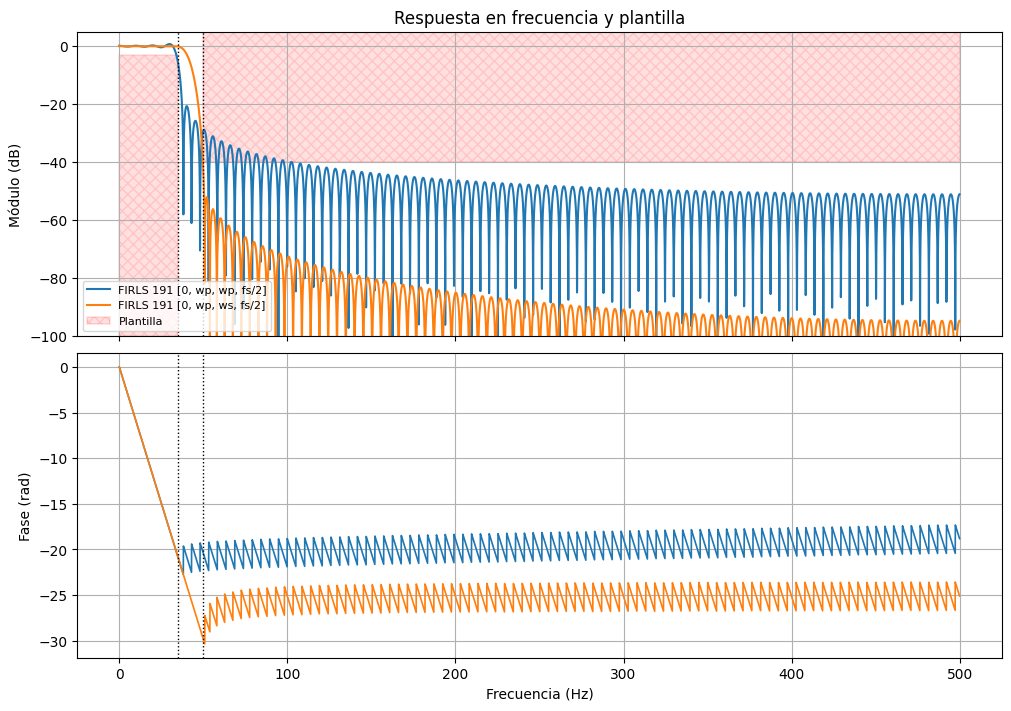

In [3]:
taps_firls = 191

b_firls_clase = sig.firls( taps_firls, [0.0, wp, wp, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [1.0, 1.0], fs = fs_ecg)
b_firls = sig.firls( taps_firls, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [1.0, 1.0], fs = fs_ecg)

verificar(b_firls_clase, 'firls sin transición')
verificar(b_firls, 'firls wp-ws')

graficar_filtros([(b_firls_clase, f'FIRLS {taps_firls} [0, wp, wp, fs/2]'),
                  (b_firls, f'FIRLS {taps_firls} [0, wp, ws, fs/2]')])

Con la banda de transición bien definida ($w_p = 35$, $w_s = 50$ Hz) el LS de 191 coeficientes cumple con margen. Se ve la característica del LS: el error es grande cerca de la transición y **decae** al alejarse, porque lo que se minimiza es la energía total del error y no el máximo.

### Ponderación de bandas

Como en el ejemplo de PyTC2, pruebo enfatizar una u otra banda (con menos coeficientes, para que se note la diferencia):
- `W = [1, 1]`: original
- `W = [1, 50]`: enfatiza la banda de **rechazo** → más atenuación, más ripple en la de paso
- `W = [50, 1]`: enfatiza la banda de **paso** → menos ripple, menos atenuación

LS W=[1, 1]              taps=131   |H(wp)| =  -0.24 dB   ripple paso =  0.31 dB   max en rechazo =  -29.95 dB   -> NO cumple
LS W=[1, 50] (stop)      taps=131   |H(wp)| =  -0.76 dB   ripple paso =  0.99 dB   max en rechazo =  -40.70 dB   -> cumple
LS W=[50, 1] (paso)      taps=131   |H(wp)| =  -0.10 dB   ripple paso =  0.14 dB   max en rechazo =  -23.28 dB   -> NO cumple


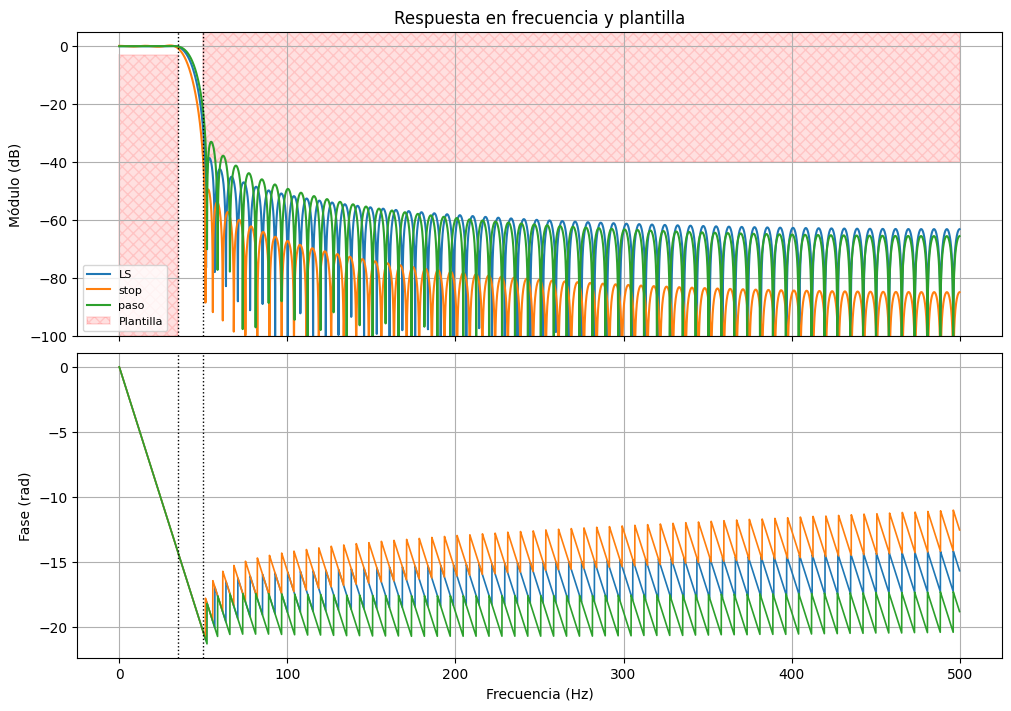

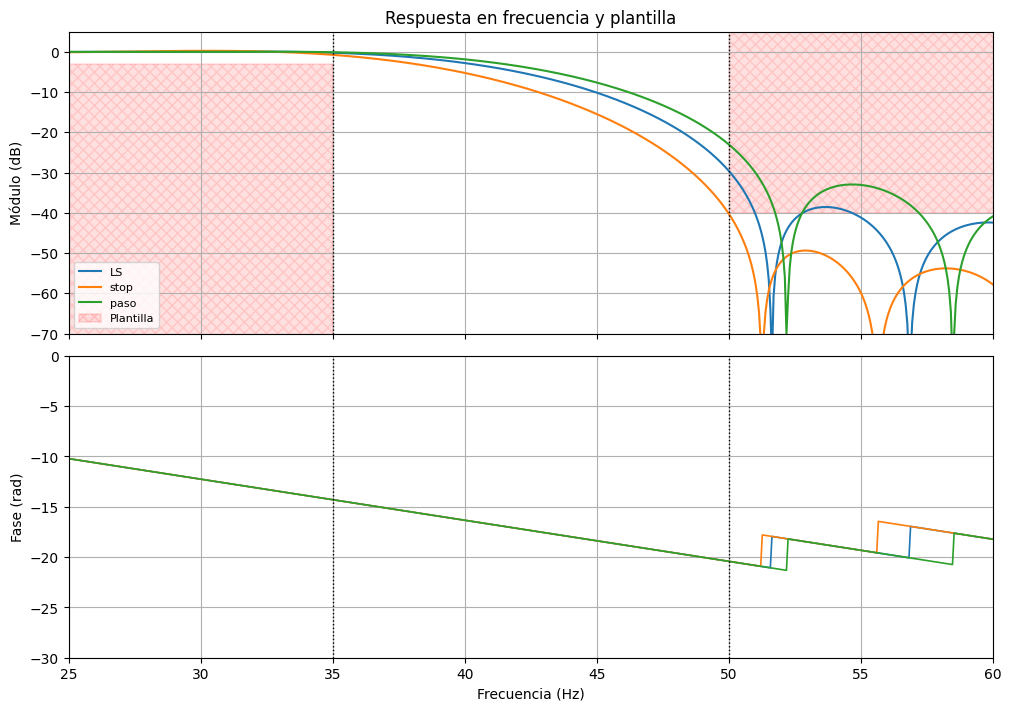

In [4]:
taps_ls_w = 131

b_ls = sig.firls( taps_ls_w, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [1.0, 1.0], fs = fs_ecg)
b_ls_stop = sig.firls( taps_ls_w, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [1.0, 50.0], fs = fs_ecg)
b_ls_paso = sig.firls( taps_ls_w, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [50.0, 1.0], fs = fs_ecg)

verificar(b_ls, 'LS W=[1, 1]')
verificar(b_ls_stop, 'LS W=[1, 50] (stop)')
verificar(b_ls_paso, 'LS W=[50, 1] (paso)')

graficar_filtros([(b_ls, 'LS'), (b_ls_stop, 'stop'), (b_ls_paso, 'paso')])
graficar_filtros([(b_ls, 'LS'), (b_ls_stop, 'stop'), (b_ls_paso, 'paso')], zoom=True)

### Ajuste hecho en clase: correr los bordes y subir el peso del rechazo

En clase se buscó que el LS de **131 coeficientes** llegue a los 40 dB corriendo los bordes de la transición dentro de la zona libre (entre $w_p$ y $w_s$) y dándole mucho peso a la banda de rechazo:
- `bands = [0, wp+3, wp+5, fs/2]`, `W = [1, 100]`
- `bands = [0, wp+6, wp+7, fs/2]`, `W = [1, 500]`

Con un peso tan grande en el rechazo, el error se pasa casi todo a la banda de paso: aparece un ripple de varios dB, y la caída del filtro antes de 35 Hz **viola la plantilla en $w_p$**. La segunda variante sí cumple la atenuación en la banda de rechazo.

LS [wp+3, wp+5] W=100    taps=131   |H(wp)| =  -5.70 dB   ripple paso =  6.99 dB   max en rechazo =  -39.55 dB   -> NO cumple
LS [wp+6, wp+7] W=500    taps=131   |H(wp)| =  -4.40 dB   ripple paso =  5.87 dB   max en rechazo =  -45.12 dB   -> NO cumple


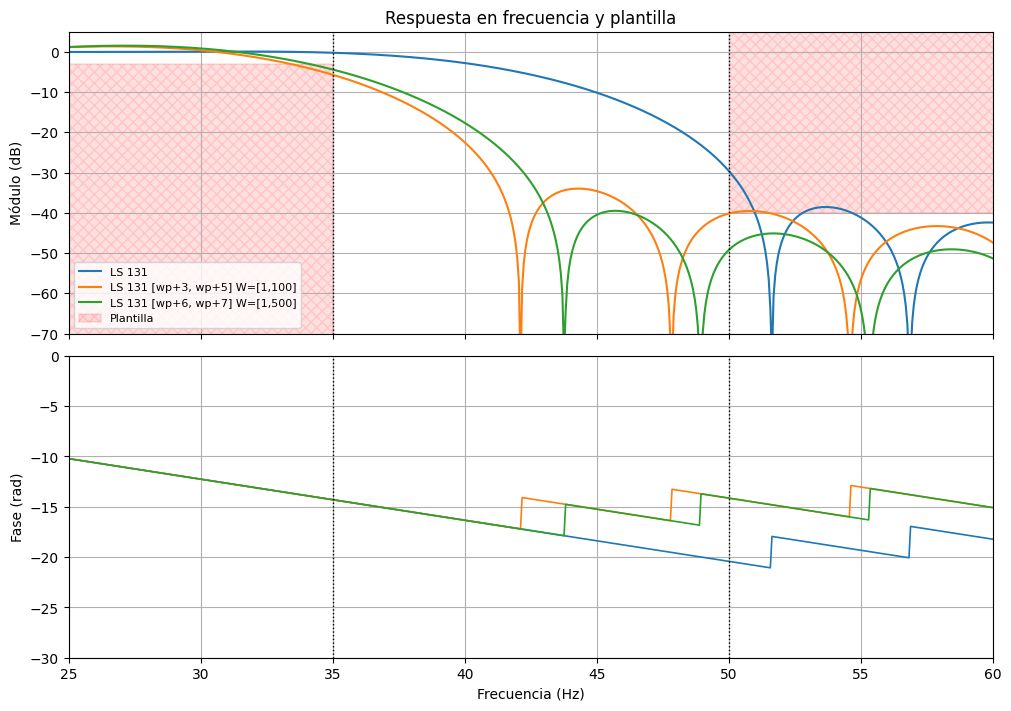

In [5]:
b_firls_clase_1 = sig.firls( taps_ls_w, [0.0, wp+3, wp+5, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [1.0, 100.0], fs = fs_ecg)
b_firls_clase_2 = sig.firls( taps_ls_w, [0.0, wp+6, wp+7, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight= [1.0, 500.0], fs = fs_ecg)

verificar(b_firls_clase_1, 'LS [wp+3, wp+5] W=100')
verificar(b_firls_clase_2, 'LS [wp+6, wp+7] W=500')

graficar_filtros([(b_ls, f'LS {taps_ls_w}'),
                  (b_firls_clase_1, f'LS {taps_ls_w} [wp+3, wp+5] W=[1,100]'),
                  (b_firls_clase_2, f'LS {taps_ls_w} [wp+6, wp+7] W=[1,500]')], zoom=True)

## 2. Parks-McClellan (equiripple): `sig.remez`

`remez(numtaps, bands, desired, weight, fs)`: mismas bandas que `firls`, pero `desired` lleva **un valor por banda** (`[1, 0]`). Minimiza el **máximo** del error ponderado, así que el error se reparte uniforme: ripple constante en toda la banda de paso y en toda la de rechazo.

El peso relaciona directamente los ripples de las dos bandas: $W_{paso}\,\delta_{paso} = W_{stop}\,\delta_{stop}$.

PM W=[1, 1]              taps=131   |H(wp)| =  -0.08 dB   ripple paso =  0.17 dB   max en rechazo =  -40.21 dB   -> cumple
PM W=[1, 10] (stop)      taps=131   |H(wp)| =  -0.31 dB   ripple paso =  0.61 dB   max en rechazo =  -49.02 dB   -> cumple
LS W=[1, 1]              taps=131   |H(wp)| =  -0.24 dB   ripple paso =  0.31 dB   max en rechazo =  -29.95 dB   -> NO cumple


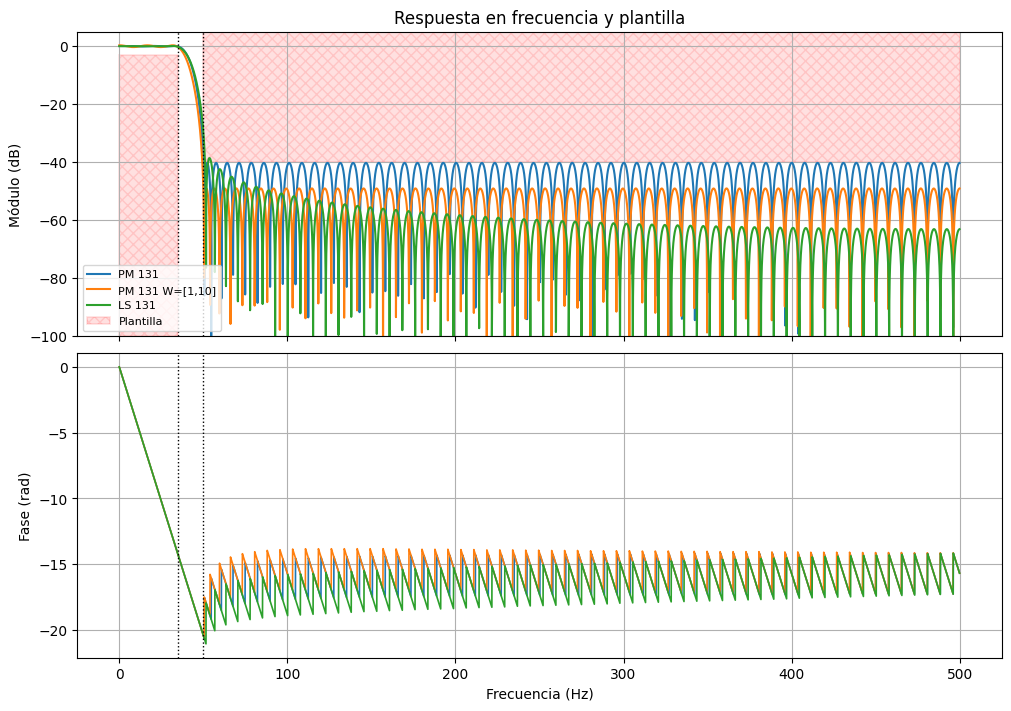

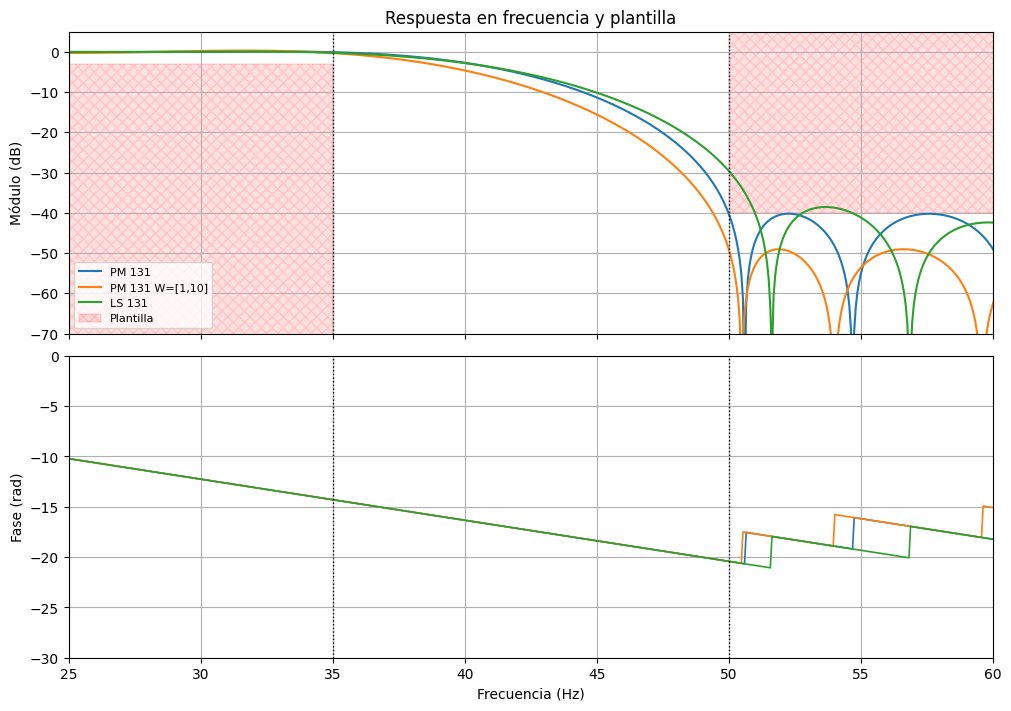

In [6]:
taps_firpm = 131

b_pm = sig.remez( taps_firpm, [0.0, wp, ws, fs_ecg/2], [1.0, 0.0], weight= [1.0, 1.0], fs = fs_ecg)
b_pm_stop = sig.remez( taps_firpm, [0.0, wp, ws, fs_ecg/2], [1.0, 0.0], weight= [1.0, 10.0], fs = fs_ecg)

verificar(b_pm, 'PM W=[1, 1]')
verificar(b_pm_stop, 'PM W=[1, 10] (stop)')
verificar(b_ls, 'LS W=[1, 1]')

graficar_filtros([(b_pm, f'PM {taps_firpm}'), (b_pm_stop, f'PM {taps_firpm} W=[1,10]'), (b_ls, f'LS {taps_ls_w}')])
graficar_filtros([(b_pm, f'PM {taps_firpm}'), (b_pm_stop, f'PM {taps_firpm} W=[1,10]'), (b_ls, f'LS {taps_ls_w}')], zoom=True)

Con la misma cantidad de coeficientes (131) y sin ponderar, el LS no llega a los 40 dB (−30 dB) y el PM sí (−40.2 dB): como el PM reparte el error parejo, no "desperdicia" atenuación lejos de la transición, y el peor caso (que es lo que pide la plantilla) queda más bajo.

## 3. Las implementaciones de PyTC2

PyTC2 trae implementaciones didácticas de ambos algoritmos: `fir_design_ls` y `fir_design_pm` (esta última basada en el algoritmo de Remez de Saramäki, según el material de Holton). Reciben el **orden** (taps − 1) y `desired` por borde. Las comparo con las de scipy para 191 coeficientes:

Convergencia exitosa!
scipy firls              taps=191   |H(wp)| =  -0.07 dB   ripple paso =  0.10 dB   max en rechazo =  -43.88 dB   -> cumple
pytc2 fir_design_ls      taps=191   |H(wp)| =  -0.06 dB   ripple paso =  0.09 dB   max en rechazo =  -45.49 dB   -> cumple
scipy remez              taps=191   |H(wp)| =  -0.02 dB   ripple paso =  0.04 dB   max en rechazo =  -52.54 dB   -> cumple
pytc2 fir_design_pm      taps=191   |H(wp)| =  -0.02 dB   ripple paso =  0.04 dB   max en rechazo =  -52.51 dB   -> cumple


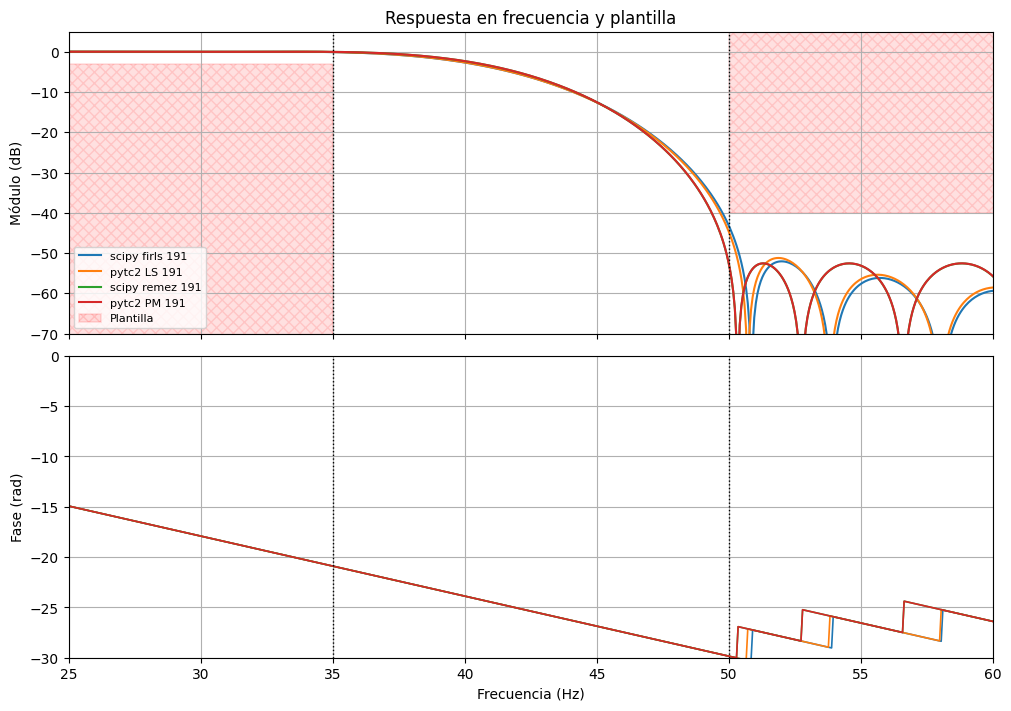

In [7]:
orden = 190   # 191 coeficientes

hh_ls = fir_design_ls(order=orden, band_edges=[0.0, wp, ws, fs_ecg/2], desired=[1.0, 1.0, 0.0, 0.0],
                      weight=[1.0, 1.0], fs=fs_ecg, filter_type='m', grid_density=16)

hh_pm, err_pm, _ = fir_design_pm(order=orden, band_edges=[0.0, wp, ws, fs_ecg/2], desired=[1.0, 1.0, 0.0, 0.0],
                                 weight=[1.0, 1.0], fs=fs_ecg, filter_type='m')

b_pm_191 = sig.remez( orden + 1, [0.0, wp, ws, fs_ecg/2], [1.0, 0.0], fs = fs_ecg)

verificar(b_firls, 'scipy firls')
verificar(hh_ls, 'pytc2 fir_design_ls')
verificar(b_pm_191, 'scipy remez')
verificar(hh_pm, 'pytc2 fir_design_pm')

graficar_filtros([(b_firls, 'scipy firls 191'), (hh_ls, 'pytc2 LS 191'),
                  (b_pm_191, 'scipy remez 191'), (hh_pm, 'pytc2 PM 191')], zoom=True)

Las implementaciones coinciden prácticamente (las pequeñas diferencias en el LS vienen de cómo cada una discretiza la grilla de frecuencias).

## 4. ¿Cuántos coeficientes necesita cada método?

Busco la **mínima cantidad (impar) de coeficientes** que cumple la plantilla con cada método. Para las ventanas uso el diseño del archivo anterior (Hamming con la transición centrada en 42–43 Hz).

In [8]:
metodos = {
    'Ventana Hamming':      lambda n: sig.firwin2(n, [0.0, 42, 43, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], window='hamming', fs=fs_ecg),
    'LS W=[1, 1]':          lambda n: sig.firls(n, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], fs=fs_ecg),
    'LS W=[1, 10]':         lambda n: sig.firls(n, [0.0, wp, ws, fs_ecg/2], [1.0, 1.0, 0.0, 0.0], weight=[1.0, 10.0], fs=fs_ecg),
    'PM W=[1, 1]':          lambda n: sig.remez(n, [0.0, wp, ws, fs_ecg/2], [1.0, 0.0], fs=fs_ecg),
    'PM W=[1, 10]':         lambda n: sig.remez(n, [0.0, wp, ws, fs_ecg/2], [1.0, 0.0], weight=[1.0, 10.0], fs=fs_ecg),
    'PM W=[1, 30]':         lambda n: sig.remez(n, [0.0, wp, ws, fs_ecg/2], [1.0, 0.0], weight=[1.0, 30.0], fs=fs_ecg),
}


def cumple_plantilla( b ):
    f, h = calc_freq_fir(b)
    mod_db = 20 * np.log10(np.maximum(np.abs(h), 1e-12))
    return np.interp(wp, f, mod_db) >= -ripple and mod_db[f >= ws].max() <= -att


minimos = {}
for nombre, disenio in metodos.items():
    for n in range(41, 301, 2):
        if cumple_plantilla(disenio(n)):
            minimos[nombre] = disenio(n)
            break

for nombre, b in minimos.items():
    verificar(b, nombre)

Ventana Hamming          taps=187   |H(wp)| =  -0.21 dB   ripple paso =  0.23 dB   max en rechazo =  -40.09 dB   -> cumple
LS W=[1, 1]              taps=179   |H(wp)| =  -0.08 dB   ripple paso =  0.10 dB   max en rechazo =  -40.16 dB   -> cumple
LS W=[1, 10]             taps=147   |H(wp)| =  -0.33 dB   ripple paso =  0.43 dB   max en rechazo =  -40.15 dB   -> cumple
PM W=[1, 1]              taps=131   |H(wp)| =  -0.08 dB   ripple paso =  0.17 dB   max en rechazo =  -40.21 dB   -> cumple
PM W=[1, 10]             taps= 95   |H(wp)| =  -0.82 dB   ripple paso =  1.58 dB   max en rechazo =  -40.74 dB   -> cumple
PM W=[1, 30]             taps= 73   |H(wp)| =  -2.89 dB   ripple paso =  5.05 dB   max en rechazo =  -40.40 dB   -> cumple


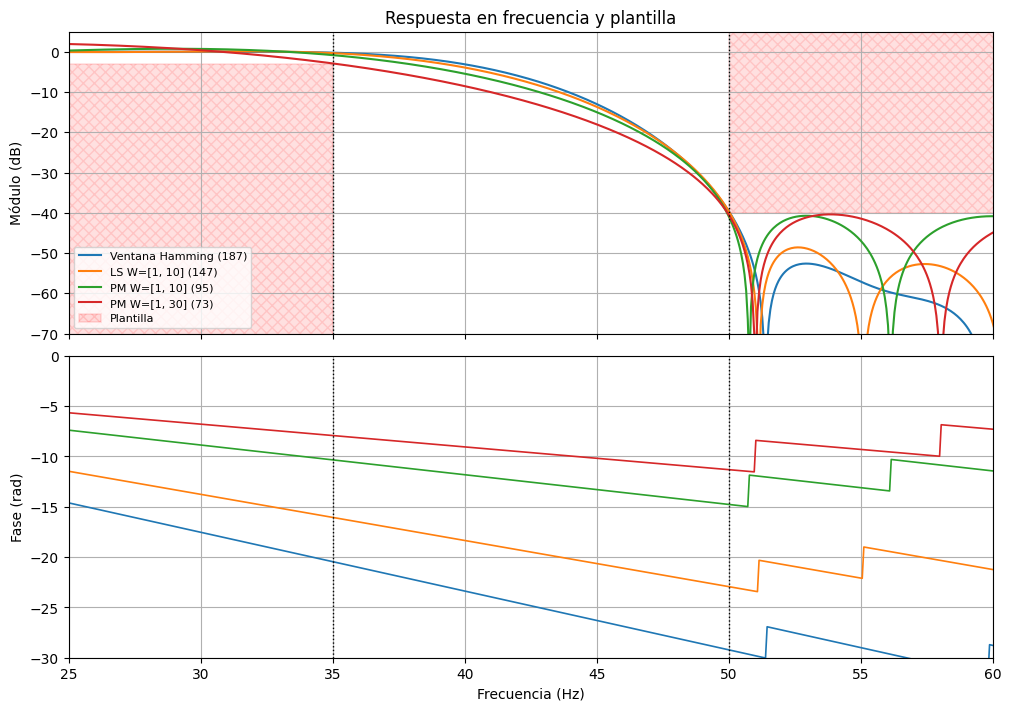

In [9]:
graficar_filtros([(b, f'{nombre} ({len(b)})') for nombre, b in minimos.items()
                  if nombre in ('Ventana Hamming', 'LS W=[1, 10]', 'PM W=[1, 10]', 'PM W=[1, 30]')], zoom=True)

El PM con `W = [1, 30]` aprovecha toda la tolerancia de la plantilla: cae hasta casi −3 dB en $w_p$ (el límite de la plantilla) y además sobrepasa los 0 dB, con unos 5 dB de ripple total en la banda de paso, a cambio de llegar a los 40 dB con muchos menos coeficientes. Para un ECG ese ripple sería excesivo (deforma la amplitud de las ondas); `W = [1, 10]` es un compromiso más razonable.

## 5. Aplicación al ECG

Comparo el PM `W = [1, 10]` (el más corto con ripple razonable), el LS de 191 y la ventana Hamming de mínima longitud. Todos son de fase lineal: compenso el retardo $(N_{taps}-1)/2$ indexando `y[zoom_region + demora]`.

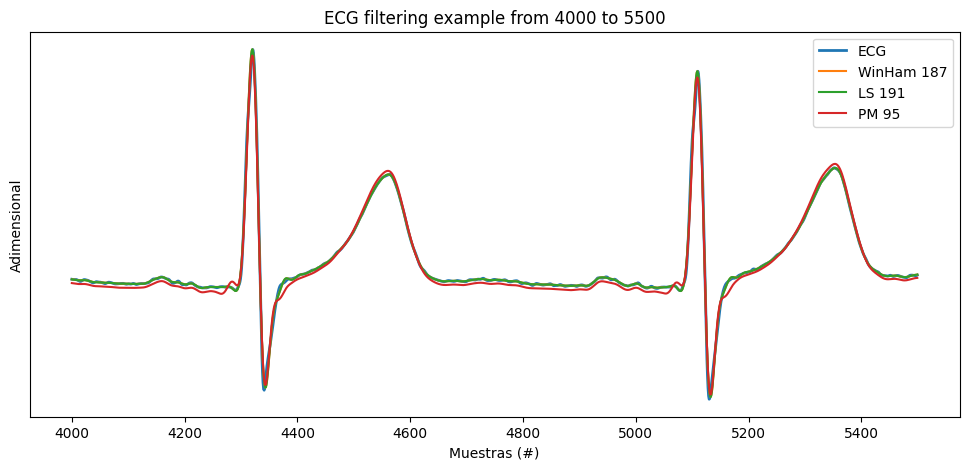

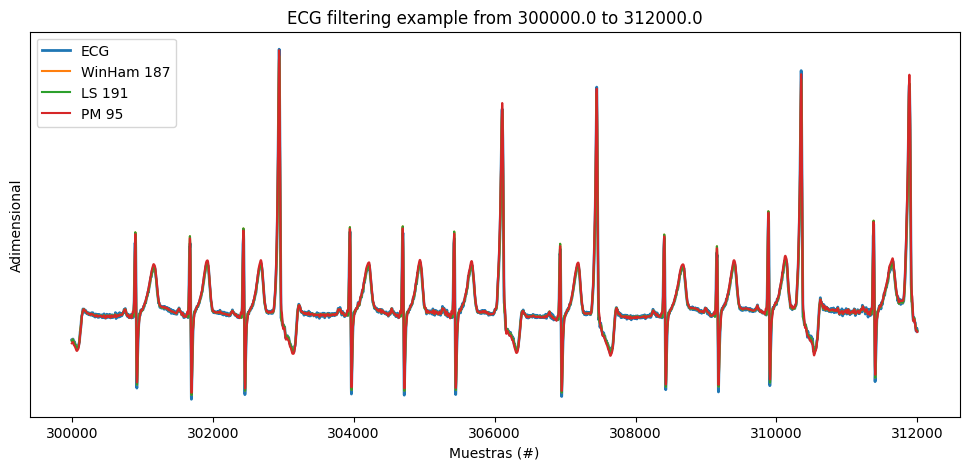

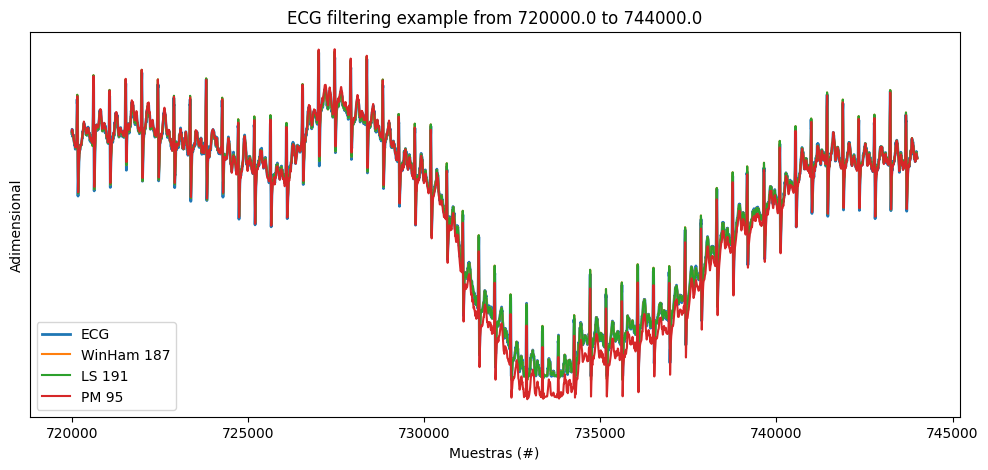

In [10]:
filtros_ecg = {
    f'WinHam {len(minimos["Ventana Hamming"])}': minimos['Ventana Hamming'],
    f'LS {taps_firls}': b_firls,
    f'PM {len(minimos["PM W=[1, 10]"])}': minimos['PM W=[1, 10]'],
}

ecg_filt = {nombre: sig.lfilter(b, 1, ecg_one_lead) for nombre, b in filtros_ecg.items()}
demoras = {nombre: (len(b) - 1)//2 for nombre, b in filtros_ecg.items()}

cant_muestras = ecg_one_lead.shape[0]
demora_max = max(demoras.values())

regs_interes = (
        [4000, 5500], # muestras (sin ruido)
        np.array([5, 5.2]) *60*fs_ecg, # minutos a muestras (con ruido)
        np.array([12, 12.4]) *60*fs_ecg, # minutos a muestras (con ruido)
        )

for ii in regs_interes:

    # intervalo limitado de 0 a cant_muestras
    zoom_region = np.arange(np.max([0, ii[0]]), np.min([cant_muestras - demora_max, ii[1]]), dtype='uint')

    plt.figure(figsize=(12, 5))
    plt.plot(zoom_region, ecg_one_lead[zoom_region], label='ECG', linewidth=2)
    for nombre, y in ecg_filt.items():
        plt.plot(zoom_region, y[zoom_region + demoras[nombre]], label=nombre)

    plt.title('ECG filtering example from ' + str(ii[0]) + ' to ' + str(ii[1]) )
    plt.ylabel('Adimensional')
    plt.xlabel('Muestras (#)')

    axes_hdl = plt.gca()
    axes_hdl.legend()
    axes_hdl.set_yticks(())

    plt.show()

## Conclusiones

- **Definir la banda de transición es indispensable** en los métodos por optimización: con `bands = [0, wp, wp, fs/2]` (sin transición) el `firls` de 191 coeficientes no cumple (−6 dB en $w_p$, −29 dB en rechazo); con `[0, wp, ws, fs/2]` cumple con margen (−43.9 dB).
- **LS vs PM:** el LS minimiza la energía del error, que queda concentrado cerca de la transición y decae lejos de ella; el PM minimiza el error máximo y lo reparte parejo (equiripple). Como la plantilla exige un **peor caso**, el PM es el más eficiente.
- **La ponderación** traslada el error de una banda a la otra: enfatizar el rechazo (`W = [1, 50]`) hace que el LS de 131 cumpla, a costa de más ripple en la banda de paso; enfatizar la banda de paso hace lo contrario.
- **Coeficientes mínimos para cumplir la plantilla:**

| Método | Coeficientes | Ripple en banda de paso |
|---|---|---|
| Ventana Hamming (`firwin2`) | 187 | 0.23 dB |
| LS `W = [1, 1]` | 179 | 0.10 dB |
| LS `W = [1, 10]` | 147 | 0.43 dB |
| PM `W = [1, 1]` | 131 | 0.17 dB |
| PM `W = [1, 10]` | 95 | 1.58 dB |
| PM `W = [1, 30]` | 73 | 5.05 dB |

  El PM es el más eficiente, y la ponderación permite cambiar ripple en la banda de paso por menos coeficientes (menor retardo y menos cálculo).
- Las implementaciones de **PyTC2** (`fir_design_ls`, `fir_design_pm`) dan prácticamente los mismos resultados que `sig.firls` y `sig.remez`.
- **En el ECG** los tres filtros comparados dan resultados muy parecidos; el PM de 95 coeficientes tiene además la menor demora (47 ms contra ~93–95 ms).